<!-- open-in-badges -->
[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/06_foundation_models/notebooks/sesion_06_3_ajuste_supervisado.ipynb) [![Abrir en Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/06_foundation_models/notebooks/sesion_06_3_ajuste_supervisado.ipynb) [![Abrir en Lightning Studio](https://pl-bolts-doc-images.s3.us-east-2.amazonaws.com/app-2/studio-badge.svg)](https://lightning.ai/new?repo_url=https%3A%2F%2Fgithub.com%2FEAFIT-IA%2Fsi7011-DeepLearning%2Fblob%2Fmain%2Fsessions%2F06_foundation_models%2Fnotebooks%2Fsesion_06_3_ajuste_supervisado.ipynb)

# SI7011 · Sesión 06 · 3. De modelo de lenguaje a asistente: ajuste supervisado (SFT) con TRL
**Juan David Martínez Vargas · Universidad EAFIT**

Acompaña las **Partes 3 y 5** de las diapositivas. Tomamos un modelo **base** (Qwen2.5-0.5B: preentrenado solo para predecir el token siguiente) y lo ajustamos con pares pregunta–respuesta en español, como se hace en la práctica: `SFTTrainer` de la librería **TRL** de Hugging Face, con la pérdida solo en la respuesta y LoRA con **peft**. Lo que las diapositivas hacen a mano (la máscara $m_t$, la pérdida $J$, $BA_r$), aquí son opciones de configuración; las celdas muestran dónde está cada una.

| Sección | Lo que cambia | Qué mirar |
|---|---|---|
| 1 | el modelo base y su tokenizador | cuántos tokens cuesta el español |
| 2 | una plantilla y el formato *prompt / completion* | qué entra al modelo y qué tiene que aprender |
| 3 | el modelo base, preguntado | ¿responde? ¿se detiene? |
| 4 | los datos: Dolly-15k en español | 2 000 pares sin contexto |
| 5 | `LoraConfig` + `SFTConfig` + `SFTTrainer` | 0.4 % de los parámetros entrenables; qué tokens cuentan en la pérdida |
| 6 | entrenar unos minutos | NLL de validación antes y después |
| 7 | antes y después | las mismas preguntas; ¿se detiene ahora? |

**Datos:** [`argilla/databricks-dolly-15k-curated-multilingual`](https://huggingface.co/datasets/argilla/databricks-dolly-15k-curated-multilingual), split `es`: las 15 000 instrucciones de Databricks Dolly, traducidas al español con DeepL (CC BY-SA 3.0). La traducción es automática: algunas respuestas suenan raras, y el modelo las imita.

**Usa GPU** (Kaggle T4 o Colab). En Kaggle activa **Internet** en *Settings*: el modelo (1 GB) y los datos se bajan de Hugging Face, y TRL se instala con `pip`. Unos 10 minutos en total. Sin GPU corre con 48 ejemplos, solo para ver que funciona.

In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')     # Kaggle "GPU T4 x2": una sola GPU (SFTTrainer no admite DataParallel)
# Kaggle trae torchao 0.10, que las versiones recientes de transformers y peft rechazan al importarse
# ("Found an incompatible version of torchao"). Este notebook no lo usa: si es viejo, se desinstala.
import os
from importlib.metadata import version, PackageNotFoundError
try:
    if tuple(int(x) for x in version('torchao').split('.')[:2]) < (0, 16):
        os.system('pip uninstall -y -q torchao')
except (PackageNotFoundError, ValueError):
    pass

import json, math, random, textwrap, time
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

try:
    import trl, peft
except ImportError:                                         # TRL no viene en Kaggle ni en Colab
    os.system('pip install -q "trl==1.16.0" peft')
    import trl, peft
import transformers, datasets
from transformers import AutoTokenizer, AutoModelForCausalLM
from datasets import load_dataset
from peft import LoraConfig
from trl import SFTConfig, SFTTrainer

random.seed(0); torch.manual_seed(0)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('transformers', transformers.__version__, '· trl', trl.__version__, '· peft', peft.__version__, '·', dev)
if dev == 'cpu':
    print('Sin GPU: el notebook corre con muy pocos ejemplos. En Kaggle: Settings → Accelerator → GPU T4.')

transformers 5.16.1 · trl 1.16.0 · peft 0.20.0 · cuda


## 1. El modelo base
Un decodificador como el de la diapositiva 32: 24 bloques pre-norm con autoatención causal, entrenado con la pérdida del token siguiente sobre unos 18 billones de tokens. Es el modelo **base**, no la versión *Instruct*: nadie le enseñó a conversar.

In [3]:
MODELO = 'Qwen/Qwen2.5-0.5B'          # el modelo BASE: solo preentrenado (token siguiente), sin SFT
tok = AutoTokenizer.from_pretrained(MODELO)
modelo = AutoModelForCausalLM.from_pretrained(MODELO, dtype=torch.float32).to(dev)
cfg = modelo.config
N_TOTAL = modelo.num_parameters()
print(f'{MODELO}: {N_TOTAL / 1e6:.0f} M parámetros · {cfg.num_hidden_layers} bloques · '
      f'd = {cfg.hidden_size} · {cfg.num_attention_heads} cabezas · |V| = {len(tok):,} · fin: {tok.eos_token!r}')

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

Qwen/Qwen2.5-0.5B: 494 M parámetros · 24 bloques · d = 896 · 14 cabezas · |V| = 151,665 · fin: '<|endoftext|>'


Su tokenizador es BPE sobre bytes (diapositivas 38–39) con unos 151 000 tokens. **Predice antes de correr:** ¿cuántos tokens necesita una frase en español frente a la misma en inglés?

In [4]:
for frase in ['Me senté en el banco del parque.', 'El ingeniero de sistemas desarrolló un algoritmo.',
              'Electroencefalografista', 'The systems engineer developed an algorithm.']:
    ids = tok.encode(frase, add_special_tokens=False)
    print(f'{len(frase):3d} caracteres → {len(ids):2d} tokens:  ' + ' | '.join(tok.decode([i]).replace(' ', '·') for i in ids))

 32 caracteres → 10 tokens:  Me | ·sent | é | ·en | ·el | ·banco | ·del | ·par | que | .
 49 caracteres → 12 tokens:  El | ·ingen | iero | ·de | ·sistemas | ·desarroll | ó | ·un | ·al | gorit | mo | .
 23 caracteres →  6 tokens:  Elect | ro | ence | fal | ograf | ista
 44 caracteres →  7 tokens:  The | ·systems | ·engineer | ·developed | ·an | ·algorithm | .


Los espacios van pegados a la palabra siguiente (`·de`). Las palabras frecuentes son un token; las raras se parten. El inglés suele necesitar menos tokens: el vocabulario se entrenó con más inglés, y cada token de más cuesta cómputo y contexto.

## 2. La plantilla y el formato de TRL
Un par (pregunta, respuesta) se convierte en una secuencia (diapositiva 68): `Usuario: <pregunta>⏎Asistente: <respuesta><fin>`. TRL lo recibe partido en dos campos:
- `prompt`: lo que el modelo **lee** (`Usuario: …⏎Asistente:`);
- `completion`: lo que el modelo tiene que **aprender a escribir**. TRL le agrega el token de fin, que es lo que le enseña a parar.

Usamos una plantilla de texto simple porque el modelo base no conversa; con un modelo *Instruct* se usa su plantilla de chat (integrador 6.6).

In [5]:
def prompt(pregunta):
    return f'Usuario: {pregunta.strip()}\nAsistente:'

def a_ejemplo(e):
    """Un par de Dolly en el formato prompt / completion de TRL. TRL agrega el token de fin a la completion."""
    return {'prompt': prompt(e['instruction']), 'completion': ' ' + e['response'].strip()}

print(a_ejemplo({'instruction': '¿Qué es un átomo?', 'response': 'Partícula mínima de un elemento químico.'}))

{'prompt': 'Usuario: ¿Qué es un átomo?\nAsistente:', 'completion': ' Partícula mínima de un elemento químico.'}


## 3. El modelo base, preguntado
**Predice** (diapositiva 47): el modelo solo aprendió a continuar texto. Con `Usuario: ¿Qué es un átomo?⏎Asistente:`, ¿responde? ¿Se detiene, o sigue escribiendo? Generamos con greedy (diapositiva 46) y como máximo 120 tokens.

In [6]:
@torch.no_grad()
def responder(m, pregunta, max_nuevos=120):
    """Greedy (diapositiva 46). Devuelve el texto y si el modelo produjo el token de fin."""
    x = tok(prompt(pregunta), return_tensors='pt').to(dev)
    out = m.generate(**x, max_new_tokens=max_nuevos, do_sample=False, eos_token_id=tok.eos_token_id,
                     pad_token_id=tok.eos_token_id)
    nuevos = out[0, x['input_ids'].shape[1]:]
    return tok.decode(nuevos, skip_special_tokens=True).strip(), bool((nuevos == tok.eos_token_id).any())

def mostrar(q, r, paro, ancho=100):
    print('▶', q)
    print(textwrap.indent(textwrap.fill(r.replace('\n', ' ⏎ ')[:700], ancho), '   '))
    print('   se detuvo:', 'sí' if paro else 'NO, llegó al límite de tokens')
    print()

PREGUNTAS = ['¿Qué es un átomo?',
             'Dame tres ideas para ahorrar agua en casa.',
             '¿Cuál es la diferencia entre el clima y el tiempo atmosférico?',
             'Clasifica estos animales en mamíferos o aves: perro, águila, ballena, gorrión.',
             'Escribe un haiku sobre la lluvia.']

In [7]:
antes = {}
for q in PREGUNTAS:
    antes[q] = responder(modelo, q)
    mostrar(q, *antes[q])

▶ ¿Qué es un átomo?
   Un átomo es un elemento que tiene un solo电子 y una sola protona. Un átomo es un elemento que tiene un
   solo电子 y una sola protona. Un átomo es un elemento que tiene un solo electron y una sola protona. Un
   átomo es un elemento que tiene un solo electron y una sola protona. Un átomo es un elemento que
   tiene un solo electron y una sola protona. Un átomo es un elemento que tiene un solo electron y una
   sola protona. Un átomo es un elemento que tiene un solo electron
   se detuvo: NO, llegó al límite de tokens

▶ Dame tres ideas para ahorrar agua en casa.
   ¡Claro! Aquí tienes algunas ideas para ahorrar agua en casa: ⏎  ⏎ 1. **Utiliza el agua caliente**:
   Si tienes una cama o un baño, utiliza el agua caliente para lavar tu ropa. Esto reduce el consumo de
   agua y evita que la cama se quede caliente durante mucho tiempo. ⏎  ⏎ 2. **Utiliza el agua de la
   ducha**: Si tienes una ducha, utiliza la ducha para lavar tu ropa. Esto reduce el consumo de agua y
   

Lo esperable (contrástalo con tu salida): a veces empieza una respuesta razonable, pero **no sabe cuándo parar**: se repite o inventa la conversación siguiente hasta el límite. Continuar texto y responder no son lo mismo.

## 4. Los datos
Nos quedamos con las preguntas de Dolly **sin contexto** y respuestas de hasta 700 caracteres; 200 quedan aparte para validar. `map` las lleva al formato `prompt` / `completion`.

In [8]:
DOLLY = 'argilla/databricks-dolly-15k-curated-multilingual'
crudo = load_dataset(DOLLY, split='es')
print(Counter(crudo['category']).most_common())

def util(e):
    """Sin contexto (la pregunta se responde sola) y respuestas de largo moderado."""
    return (not (e['context'] or '').strip() and 20 <= len(e['response']) <= 700
            and len(e['instruction']) <= 300)

filtrado = crudo.filter(util).shuffle(seed=0)
N_TRAIN, N_VAL = (2000, 200) if dev == 'cuda' else (48, 16)
val_crudo = filtrado.select(range(N_VAL))
train_crudo = filtrado.select(range(N_VAL, N_VAL + N_TRAIN))
train = train_crudo.map(a_ejemplo, remove_columns=train_crudo.column_names)
val = val_crudo.map(a_ejemplo, remove_columns=val_crudo.column_names)
print(f'{len(filtrado):,} ejemplos útiles · {len(train):,} para entrenar · {len(val):,} para validar')
print(train[0])

README.md:   0%|          | 0.00/8.48k [00:00<?, ?B/s]

data/de-00000-of-00001-b043739d21afba4d.(…): reconstructing file:   0%|          |  0.00B / 16.7MB            

data/de-00000-of-00001-b043739d21afba4d.(…): downloading bytes:           |  0.00B            

data/en-00000-of-00001-38c55f997090aa24.(…): reconstructing file:   0%|          |  0.00B / 15.5MB            

data/en-00000-of-00001-38c55f997090aa24.(…): downloading bytes:           |  0.00B            

...

[('open_qa', 3611), ('general_qa', 2191), ('classification', 2136), ('closed_qa', 1823), ('brainstorming', 1768), ('information_extraction', 1512), ('summarization', 1263), ('creative_writing', 711)]


Filter:   0%|          | 0/15015 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

7,967 ejemplos útiles · 2,000 para entrenar · 200 para validar
{'prompt': 'Usuario: ¿Qué ventajas tiene bailar salsa?\nAsistente:', 'completion': ' Bailar salsa es una forma estupenda de conocer gente nueva. Ya sea mediante clases de baile o saliendo a un club de salsa, la naturaleza social del baile de salsa lo convierte en una buena forma de ampliar tu círculo social y aumentar tus actividades sociales.'}


## 5. LoRA, la configuración y el entrenador
Tres objetos:
- `LoraConfig` (peft): $r = 16$ sobre $W_Q, W_K, W_V, W_O$ de los 24 bloques (diapositiva 66). `SFTTrainer` congela el modelo base y agrega $BA_r$, con $B = 0$ al empezar;
- `SFTConfig` (TRL): los hiperparámetros del loop de siempre (AdamW, warmup y coseno, clipping, precisión mixta) y, sobre todo, `completion_only_loss=True`: **la pérdida solo cuenta la respuesta** (diapositiva 71);
- `SFTTrainer`: tokeniza, arma los lotes, entrena y evalúa.

In [9]:
lora = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.0, task_type='CAUSAL_LM',
                  target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj'])        # W_Q, W_K, W_V, W_O
args = SFTConfig(
    output_dir='sft_dolly', seed=0,
    completion_only_loss=True,               # la pérdida solo en la respuesta (diapositiva 71)
    max_length=384,
    num_train_epochs=1, per_device_train_batch_size=8, per_device_eval_batch_size=8,
    learning_rate=2e-4, lr_scheduler_type='cosine', warmup_steps=20, max_grad_norm=1.0, weight_decay=0.0,
    fp16=dev == 'cuda', bf16=False,          # precisión mixta en float16: la T4 no tiene bfloat16
    eval_strategy='steps', eval_steps=50, logging_steps=10, save_strategy='no', report_to='none')
trainer = SFTTrainer(model=modelo, args=args, train_dataset=train, eval_dataset=val,
                     processing_class=tok, peft_config=lora)
trainer.model.print_trainable_parameters()

Adding EOS to train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

...

Tokenizing eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

trainable params: 2,162,688 || all params: 496,195,456 || trainable%: 0.4359


¿Dónde quedó la máscara $m_t$? En las **etiquetas** de cada lote: los tokens del prompt valen `-100` y el modelo no aprende a predecirlos. La pérdida que calcula el entrenador es exactamente la $J$ de la diapositiva 71.

In [10]:
lote = next(iter(trainer.get_train_dataloader()))
ids, etiquetas = lote['input_ids'][0], lote['labels'][0]
reales = lote['attention_mask'][0].bool() if 'attention_mask' in lote else torch.ones_like(ids, dtype=torch.bool)
print('entra al modelo:     ', repr(tok.decode(ids[reales])))
print('cuenta en la pérdida:', repr(tok.decode(ids[etiquetas != -100])))
print(f'{int((etiquetas != -100).sum())} de {int(reales.sum())} tokens tienen etiqueta; el resto vale -100 y no cuenta')

entra al modelo:      'Usuario: ¿Cómo puedo ir de Singapur a San Francisco?\nAsistente: Hay varios vuelos directos de Singapur a San Francisco. Singapore Airlines y United Airlines ofrecen varios vuelos directos diarios que tardan unas 17h en cada sentido. Alternativamente, podrías tomar un vuelo de conexión en Japón que tardaría unas 20h. Conducir no funcionaría porque no hay una ruta terrestre continua de Singapur a San Francisco. Podrías tomar un barco, pero tendrías que encontrar uno que navegue por esta ruta, además de tardar 2 semanas en hacer el viaje.<|endoftext|>'
cuenta en la pérdida: ' Hay varios vuelos directos de Singapur a San Francisco. Singapore Airlines y United Airlines ofrecen varios vuelos directos diarios que tardan unas 17h en cada sentido. Alternativamente, podrías tomar un vuelo de conexión en Japón que tardaría unas 20h. Conducir no funcionaría porque no hay una ruta terrestre continua de Singapur a San Francisco. Podrías tomar un barco, pero tendrías que encon

Lo mismo, token por token, como la tabla de la diapositiva 69 pero con el modelo real: la pérdida $L_t$ de cada posición en un par corto de validación, y cuáles cuentan.

In [11]:
def papeles(pregunta, respuesta):
    """Ids pedazo por pedazo y el papel de cada token: 0 plantilla, 1 pregunta, 2 respuesta (con el fin)."""
    ids, papel = [], []
    for texto, k in [('Usuario:', 0), (' ' + pregunta.strip(), 1), ('\nAsistente:', 0), (' ' + respuesta.strip(), 2)]:
        t = tok.encode(texto, add_special_tokens=False)
        ids += t; papel += [k] * len(t)
    return ids + [tok.eos_token_id], papel + [2]

corto = min((e for e in val_crudo if len(e['response']) > 40), key=lambda e: len(e['instruction']) + len(e['response']))
ids_c, papel_c = papeles(corto['instruction'], corto['response'])
with torch.no_grad():                          # B = 0 todavía: es el modelo base
    z = trainer.model(input_ids=torch.tensor([ids_c], device=dev)).logits[0, :-1].float()
    L_c = F.cross_entropy(z, torch.tensor(ids_c[1:], device=dev), reduction='none').tolist()
print(f'{"t":>3}  {"objetivo":<16} {"L_t":>6}  cuenta')
for t in range(len(L_c)):
    print(f'{t + 1:>3}  {tok.decode([ids_c[t + 1]])!r:<16} {L_c[t]:6.2f}   {"sí" if papel_c[t + 1] == 2 else ""}')
Lc, mc = np.array(L_c), np.array(papel_c[1:]) == 2
print(f'\npromedio de las {len(Lc)} posiciones: {Lc.mean():.2f} · solo la respuesta ({mc.sum()}): {Lc[mc].mean():.2f}')

  t  objetivo            L_t  cuenta
  1  ':'                4.31   
  2  ' ¿'               6.11   
  3  'Qué'              2.12   
  4  ' hace'            4.79   
  5  ' la'              2.73   
  6  ' Constit'         8.43   
  7  'ución'            0.05   
  8  '?'                1.88   
  9  '\n'               8.61   
 10  'As'               5.16   
 11  'ist'              4.25   
 12  'ente'             1.77   
 13  ':'                0.50   
 14  ' Prote'          10.09   sí
 15  'ge'               2.78   sí
 16  ' los'             2.27   sí
 17  ' derechos'        0.40   sí
 18  ' bás'             5.16   sí
 19  'icos'             0.00   sí
 20  ' de'              0.56   sí
 21  ' los'             1.38   sí
 22  ' estad'           7.63   sí
 23  'oun'              0.03   sí
 24  'id'               0.00   sí
 25  'enses'            0.01   sí
 26  '<|endoftext|>'    6.36   sí

promedio de las 26 posiciones: 3.36 · solo la respuesta (13): 2.82


Las pérdidas grandes están en la **pregunta** (el modelo no puede adivinar qué le van a preguntar) y en la respuesta. Sin la máscara, el ajuste gastaría gradiente en aprender a predecir las preguntas de Dolly.

**NLL de validación:** la misma $J$ sobre los 200 pares de validación, sin gradiente. $e^{J}$ es la perplejidad (diapositiva 74). Como $B = 0$, antes de entrenar el modelo es exactamente el base.

In [12]:
J_antes = trainer.evaluate()['eval_loss']      # B = 0 al empezar: es exactamente el modelo base
print(f'modelo base · NLL de la respuesta en validación: {J_antes:.3f} nats/token · perplejidad {math.exp(J_antes):.1f}')

Training Loss,Validation Loss,Step,Entropy,Mean Token Accuracy,Num Tokens
No log,2.059950,0,2.029220,0.575821,0.000000


modelo base · NLL de la respuesta en validación: 2.060 nats/token · perplejidad 7.8


## 6. Entrenar
Una época sobre 2 000 pares: 250 pasos de 8 ejemplos, con la NLL de validación cada 50.

In [13]:
t0 = time.time()
trainer.train()
SEGUNDOS = time.time() - t0
MEMORIA = torch.cuda.max_memory_allocated() / 2**30 if dev == 'cuda' else float('nan')
J_despues = trainer.evaluate()['eval_loss']
print(f'\n{SEGUNDOS / 60:.1f} min · memoria pico {MEMORIA:.1f} GB · NLL de validación {J_antes:.3f} → {J_despues:.3f} '
      f'(perplejidad {math.exp(J_antes):.1f} → {math.exp(J_despues):.1f})')

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
50,1.970541,1.925570,2.002627,0.600106,38018.000000
100,1.959684,1.916660,1.975458,0.600573,77412.000000
150,2.020626,1.908673,1.966480,0.604267,117932.000000
200,1.923196,1.904166,1.944209,0.604142,156394.000000
250,2.005536,1.903495,1.943385,0.604374,194881.000000


Training Loss,Validation Loss,Step,Entropy,Mean Token Accuracy,Num Tokens
2.005536,1.903495,250,1.943385,0.604374,194881.000000



2.0 min · memoria pico 2.3 GB · NLL de validación 2.060 → 1.903 (perplejidad 7.8 → 6.7)


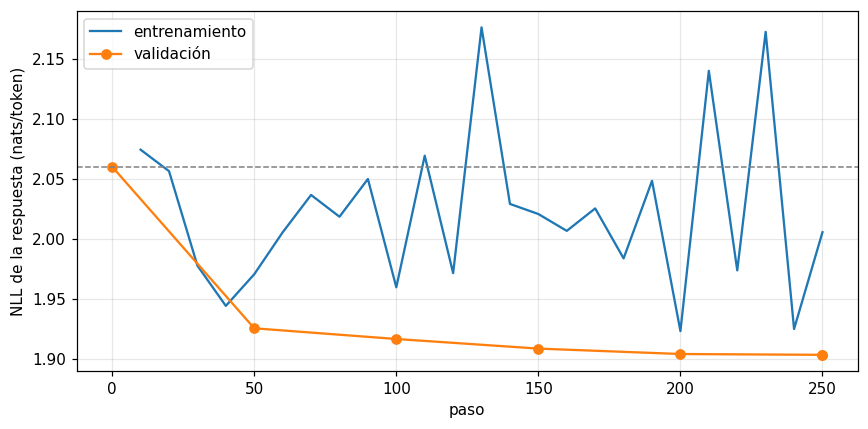

In [14]:
log = trainer.state.log_history
tr = [(r['step'], r['loss']) for r in log if 'loss' in r]
ev = [(0, J_antes)] + [(r['step'], r['eval_loss']) for r in log if 'eval_loss' in r]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(*zip(*tr), label='entrenamiento')
ax.plot(*zip(*ev), 'o-', label='validación')
ax.axhline(J_antes, color='gray', ls='--', lw=1)
ax.set_xlabel('paso'); ax.set_ylabel('NLL de la respuesta (nats/token)'); ax.legend()
plt.tight_layout(); plt.show()

La NLL de validación baja sobre todo en los primeros pasos: el modelo aprende rápido el **formato** (cuándo empieza y cuándo termina una respuesta, el registro de Dolly) y mucho más despacio el contenido. 250 pasos y 2 millones de parámetros no le enseñan hechos nuevos.

## 7. Antes y después
Las mismas preguntas de la sección 3, con el mismo greedy.

In [15]:
m = trainer.model
m.eval()
despues = {}
for q in PREGUNTAS:
    despues[q] = responder(m, q)
    print('ANTES  ', end=''); mostrar(q, *antes[q])
    print('DESPUÉS', end=''); mostrar(q, *despues[q])
    print('-' * 100)

ANTES  ▶ ¿Qué es un átomo?
   Un átomo es un elemento que tiene un solo电子 y una sola protona. Un átomo es un elemento que tiene un
   solo电子 y una sola protona. Un átomo es un elemento que tiene un solo electron y una sola protona. Un
   átomo es un elemento que tiene un solo electron y una sola protona. Un átomo es un elemento que
   tiene un solo electron y una sola protona. Un átomo es un elemento que tiene un solo electron y una
   sola protona. Un átomo es un elemento que tiene un solo electron
   se detuvo: NO, llegó al límite de tokens

DESPUÉS▶ ¿Qué es un átomo?
   Un átomo es un elemento que tiene un número de protones y un número de electrones.
   se detuvo: sí

----------------------------------------------------------------------------------------------------
ANTES  ▶ Dame tres ideas para ahorrar agua en casa.
   ¡Claro! Aquí tienes algunas ideas para ahorrar agua en casa: ⏎  ⏎ 1. **Utiliza el agua caliente**:
   Si tienes una cama o un baño, utiliza el agua caliente para l

Y una medida simple de lo que más cambió: en cuántas preguntas de validación el modelo **se detiene solo**. `disable_adapter()` apaga $BA_r$ y deja el modelo base sin cargarlo otra vez.

In [16]:
N_PARO = 12 if dev == 'cuda' else 3
preguntas_val = [e['instruction'] for e in val_crudo.select(range(N_PARO))]
with m.disable_adapter():                      # el modelo base, sin cargarlo otra vez
    paro_antes = [responder(m, q)[1] for q in preguntas_val]
paro_despues = [responder(m, q)[1] for q in preguntas_val]
print(f'se detiene solo, en {N_PARO} preguntas de validación: base {sum(paro_antes)}/{N_PARO} · '
      f'con LoRA {sum(paro_despues)}/{N_PARO}')
e = val_crudo[0]
print('\nUna pregunta de validación, con la respuesta de Dolly al lado:')
mostrar(e['instruction'], *responder(m, e['instruction']))
print('   Dolly:', textwrap.shorten(e['response'], 300))

se detiene solo, en 12 preguntas de validación: base 2/12 · con LoRA 9/12

Una pregunta de validación, con la respuesta de Dolly al lado:
▶ Dame una lista de los suplementos más consensuados que son eficaces para mantener la salud general
   1. Vitamina D ⏎ 2. Vitamina C ⏎ 3. Vitamina E ⏎ 4. Vitamina B ⏎ 5. Vitamina B12 ⏎ 6. Vitamina A ⏎ 7.
   Vitamina B6 ⏎ 8. Vitamina B1 ⏎ 9. Vitamina B2 ⏎ 10. Vitamina B3 ⏎ 11. Vitamina B5 ⏎ 12. Vitamina B10
   ⏎ 13. Vitamina B12 ⏎ 14. Vitamina B17 ⏎ 15. Vitamina B19 ⏎ 16. Vitamina B20
   se detuvo: NO, llegó al límite de tokens

   Dolly: 1) Vitamina D 2) Aceite de pescado Omega-3 3) Monohidrato de creatina 4) Multivitamínico *Descargo de responsabilidad: existen otros innumerables suplementos; sin embargo, décadas de investigación parecen haber formado un consenso sobre la eficacia de éstos


In [17]:
m.save_pretrained('lora_dolly_es')                                   # solo el adaptador: unos MB
N_LORA = sum(p.numel() for p in m.parameters() if p.requires_grad)
json.dump({'modelo': MODELO, 'n_train': len(train), 'n_val': len(val), 'pasos': trainer.state.global_step,
           'parametros': N_TOTAL, 'entrenables': N_LORA, 'segundos': SEGUNDOS, 'memoria_gb': MEMORIA,
           'J_antes': J_antes, 'J_despues': J_despues, 'hist': {'train': tr, 'val': ev},
           'paro_antes': sum(paro_antes), 'paro_despues': sum(paro_despues), 'n_paro': N_PARO,
           'antes': {q: list(v) for q, v in antes.items()}, 'despues': {q: list(v) for q, v in despues.items()},
           'por_token': {'piezas': [tok.decode([i]) for i in ids_c], 'papel': papel_c, 'L': L_c}},
          open('resultados_sft.json', 'w'), ensure_ascii=False, indent=1)
print('guardado: lora_dolly_es/ y resultados_sft.json')

guardado: lora_dolly_es/ y resultados_sft.json


Para usarlo sin peft, `merge_and_unload()` suma $\frac{\alpha}{r}BA_r$ a cada $W_0$ y devuelve un modelo normal del mismo tamaño: el modelo ajustado cuesta lo mismo al generar que el base (diapositiva 66).

In [ ]:
x = tok(prompt(PREGUNTAS[0]), return_tensors='pt').to(dev)
with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16, enabled=dev == 'cuda'):
    p_lora = m(**x).logits.float().softmax(-1)
    fusionado = m.merge_and_unload()           # W0 + (alpha/r) B A_r en cada matriz: un modelo normal
    p_fus = fusionado(**x).logits.float().softmax(-1)
print(f'tipo: {type(fusionado).__name__} · diferencia máxima en las probabilidades: '
      f'{(p_lora - p_fus).abs().max().item():.1e} (redondeo de float16) · '
      f'mismo token más probable en todas las posiciones: {bool((p_lora.argmax(-1) == p_fus.argmax(-1)).all())}')

## Tu turno · 15 minutos
1. **Sin la máscara.** Pon `completion_only_loss=False` (la pérdida cuenta también la pregunta), vuelve a crear el entrenador desde la sección 5 y entrena. Compara la NLL de validación (que siempre se mide sobre la respuesta) y las respuestas.
2. **El rango.** Prueba `r = 4` y `r = 64` en `LoraConfig`. ¿Cuántos parámetros entrenables? ¿Cambia la NLL?
3. **Menos datos.** Entrena con `N_TRAIN = 200`. ¿Cuánto del cambio de la sección 7 se conserva?
4. **Con contexto.** Agrega a `prompt` un trozo `Contexto:` y usa también las preguntas con `context` (`closed_qa`, `summarization`). ¿En qué campo van esos tokens, y por qué?

**Para pensar.** Aquí la respuesta "correcta" es la de Dolly. En el **ejercicio integrador** (notebook 6.6), el objetivo es que un modelo que ya conversa responda **con un estilo**. ¿Bastará con pedírselo en el *prompt*?

In [ ]:
# Tu turno

### Referencias
- Ouyang et al. (2022), *Training language models to follow instructions with human feedback*, NeurIPS (SFT y luego preferencias).
- Hu et al. (2021), *LoRA: Low-Rank Adaptation of Large Language Models*, ICLR 2022.
- Conover et al. (2023), *Free Dolly: Introducing the World's First Truly Open Instruction-Tuned LLM*, Databricks.
- Qwen Team (2024), *Qwen2.5 Technical Report*.
- Documentación de [TRL](https://huggingface.co/docs/trl) (`SFTTrainer`) y de [peft](https://huggingface.co/docs/peft) (`LoraConfig`).